# EgoHandBench demo

Local WiLoR image, video and streaming inference. Each call returns `mano` parameters and `joint` predictions (16 MANO joints and 5 fingertips) in camera-space metres.

In [1]:
from pathlib import Path

import numpy as np
from IPython.display import Video, display
from PIL import Image
from tqdm.auto import tqdm

from baselines.hand_detector import HandDetector
from utils.io import load_npz, load_sample, save_npz, save_video
from utils.visualizer import Visualizer

model = HandDetector("wilor", version="official")  # e.g. HandDetector("hamer", version="egohandbench"), HandDetector("ace_ego_hand")
visualizer = Visualizer()
output = Path("results/sample/wilor/official")


## Image

MANO mesh (left) and joints (right).


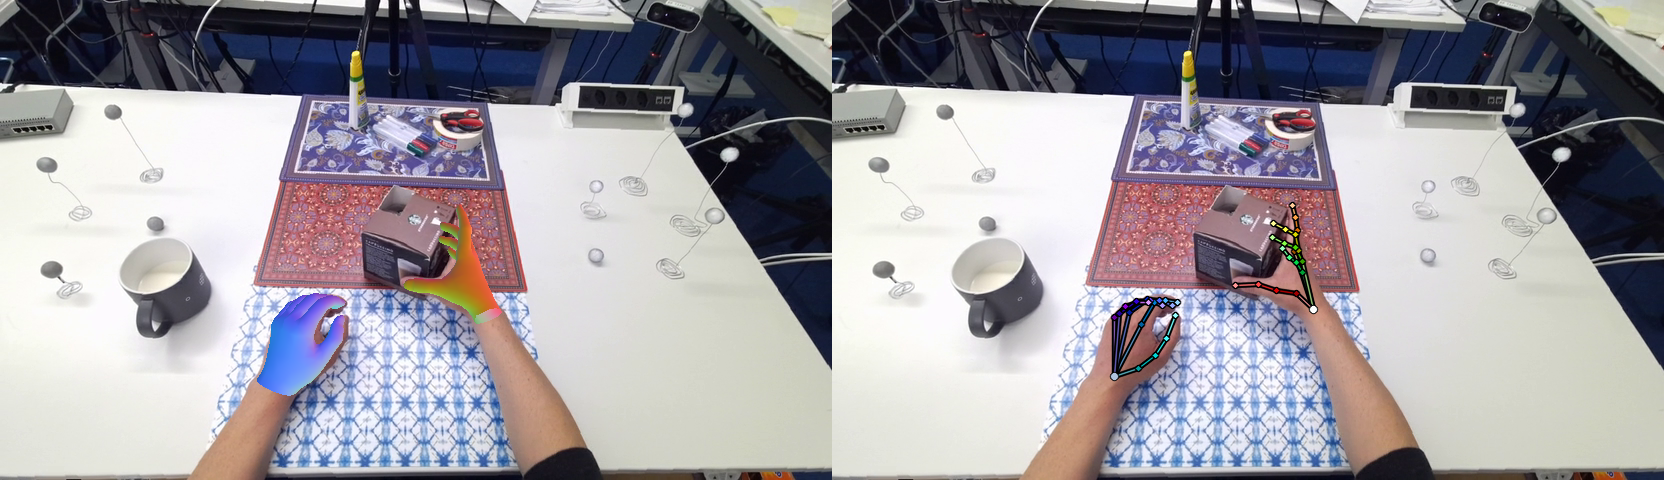

In [2]:
image = load_sample("datasets/sample/image.png", "datasets/sample/image_camera.json")
prediction = model.inference_offline(image)
mesh = visualizer.render_mano(prediction["mano"], image)
joints = visualizer.render_joint(prediction["joint"], image)
display(Image.fromarray(np.concatenate((mesh[0], joints[0]), axis=1)))


## Video

An 81-frame H2O clip. Offline calls reset clip state automatically. Save and reload either prediction dictionary as NPZ.

In [3]:
sample = load_sample("datasets/sample/h2o.mp4", "datasets/sample/h2o_camera.json")
prediction = model.inference_offline(sample)

for source, arrays in prediction.items():
    save_npz(output / source / (sample["name"] + ".npz"), arrays)
prediction = {source: load_npz(output / source / (sample["name"] + ".npz")) for source in ("mano", "joint")}

mesh = visualizer.render_mano(prediction["mano"], sample)
joints = visualizer.render_joint(prediction["joint"], sample)
preview = np.concatenate((mesh, joints), axis=2)
save_video(output / "video.mp4", preview, sample["camera"].fps)
display(Video(filename=str(output / "video.mp4"), embed=True))


## Stream

Process the same video one frame at a time. Reset stateful models such as EgoForce between clips. WiLoR needs no reset.


In [4]:
video, camera = sample["video"], sample["camera"]
preview = []
for i in tqdm(range(len(video)), desc="Streaming", unit="frame"):
    frame = {"image": video[i], "camera": camera.slice([i])}
    prediction = model.inference_stream(frame)
    mesh = visualizer.render_mano(prediction["mano"], frame)
    joints = visualizer.render_joint(prediction["joint"], frame)
    preview.append(np.concatenate((mesh[0], joints[0]), axis=1))
save_video(output / "stream.mp4", np.asarray(preview), camera.fps)
display(Video(filename=str(output / "stream.mp4"), embed=True))